## 1. Object Detection with YOLOv5 (Using Pretrained Weights)
### Question
**Problem:** Detect objects using pre-trained YOLOv5 model.

### Answer

Downloaded sample.jpg

image 1/1 C:\HOPE AI\AI TAMIL COURSE\DEEP LEARNING SET QUESTIONS\4.Coding\sample.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 251.2ms
Speed: 16.1ms preprocess, 251.2ms inference, 19.3ms postprocess per image at shape (1, 3, 640, 480)

Detected 6 objects:
  bus        87.3%  box=(23, 231, 805, 757)
  person     86.6%  box=(49, 399, 245, 903)
  person     85.3%  box=(669, 392, 810, 877)
  person     82.5%  box=(222, 406, 345, 858)
  person     26.1%  box=(0, 551, 63, 873)
  stop sign  25.5%  box=(0, 254, 33, 325)

Saved image with boxes as result.jpg


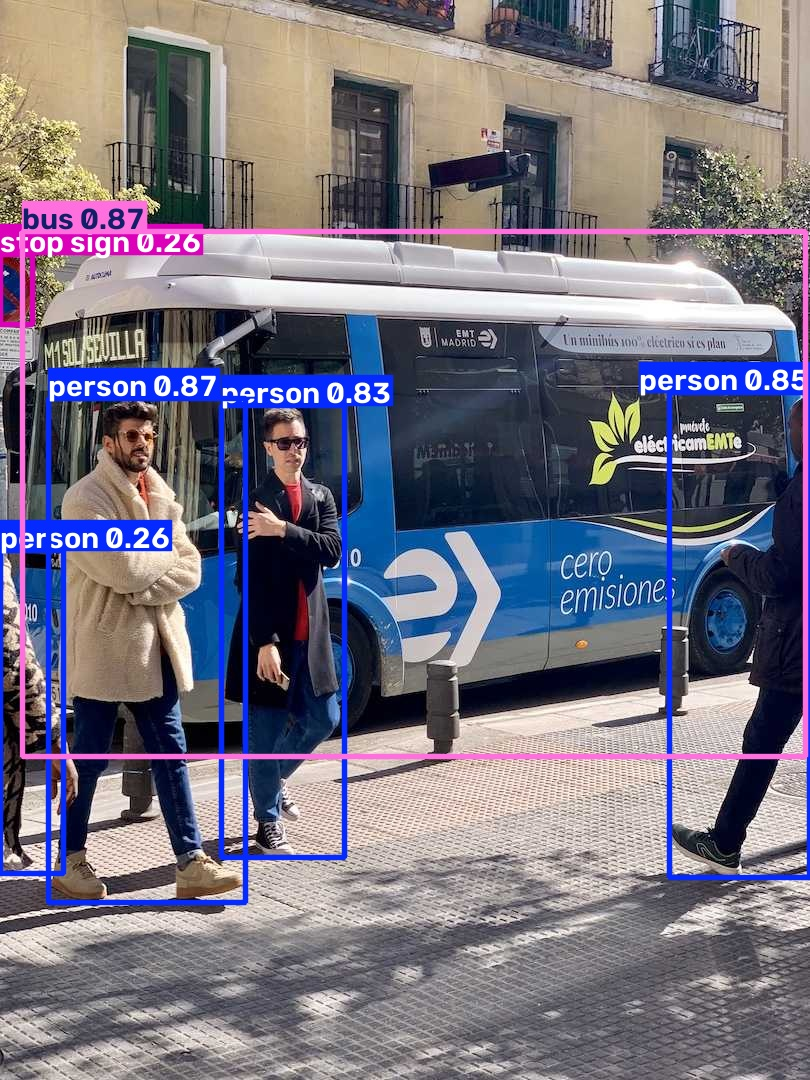

In [2]:
import os
import urllib.request
from ultralytics import YOLO

# Load a pretrained YOLO model
# Explanation: yolov8n = "nano" version, smallest and fastest (good for a laptop).
# It is downloaded automatically the first time (~6 MB).
model = YOLO("yolov8n.pt")

# Get a sample image (only the first time)
# Explanation: downloads the official Ultralytics test photo (bus + people)
image_path = "sample.jpg"
if not os.path.exists(image_path):
    urllib.request.urlretrieve("https://ultralytics.com/images/bus.jpg", image_path)
    print("Downloaded sample.jpg")

# Run detection on the image
# Explanation: conf=0.25 means show only detections with at least 25% confidence
results = model(image_path, conf=0.25)

# Print every detected object
# Explanation: results is a list (one item per image), so we loop through it
for r in results:
    print(f"\nDetected {len(r.boxes)} objects:")
    for box in r.boxes:
        class_id = int(box.cls[0])                 # class number
        class_name = model.names[class_id]         # class name, e.g. "person"
        confidence = float(box.conf[0])            # 0 to 1
        x1, y1, x2, y2 = box.xyxy[0].tolist()      # box corners in pixels
        print(f"  {class_name:10s} {confidence * 100:.1f}%  "
              f"box=({x1:.0f}, {y1:.0f}, {x2:.0f}, {y2:.0f})")

    # Save the image with boxes drawn on it
    r.save(filename="result.jpg")
    print("\nSaved image with boxes as result.jpg")

# Show the result inside the notebook
from IPython.display import Image as ShowImage, display
display(ShowImage("result.jpg", width=500))

## 2. Preprocessing Image for ResNet Input
### Question
**Problem:** Write a function to preprocess image for pretrained ResNet.

### Answer

In [3]:
!pip install torch torchvision

import torch
from torchvision import transforms, models
from PIL import Image

def preprocess_image(img_path):
    # Explanation: open the image and convert to RGB
    # (some images are grayscale or have 4 channels; ResNet needs 3)
    image = Image.open(img_path).convert("RGB")

    transform = transforms.Compose([
        # Explanation: ResNet was trained on 224 x 224 images
        transforms.Resize((224, 224)),
        # Explanation: converts the image to a tensor of shape (3, 224, 224)
        # and scales pixel values from 0-255 to 0-1
        transforms.ToTensor(),
        # Explanation: normalize with ImageNet mean and std (per R, G, B channel),
        # the same values used when ResNet was trained
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])

    # Explanation: unsqueeze(0) adds the batch dimension -> (1, 3, 224, 224)
    return transform(image).unsqueeze(0)


# ---- Test the function with a pretrained ResNet50 ----
img_tensor = preprocess_image("sample.jpg")
print("Input shape:", img_tensor.shape)        # torch.Size([1, 3, 224, 224])

weights = models.ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)
model.eval()                                   # Explanation: evaluation mode (no training)

with torch.no_grad():                          # Explanation: no gradients needed for prediction
    output = model(img_tensor)

pred_id = output.argmax(dim=1).item()
print("Predicted class:", weights.meta["categories"][pred_id])


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Input shape: torch.Size([1, 3, 224, 224])
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\nisha/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:39<00:00, 2.62MB/s]


Predicted class: minibus


## 3. CNN for CIFAR-10 Classification
### Question
**Problem:** Build a CNN model to classify CIFAR-10 images.

### Answer

In [1]:
!pip install tensorflow datasets matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Keras download failed, using Hugging Face instead...


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

C:\Users\nisha\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\nisha\.cache\huggingface\hub\datasets--uoft-cs--cifar10. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\nisha\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system u

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Train: (50000, 32, 32, 3)  Test: (10000, 32, 32, 3)


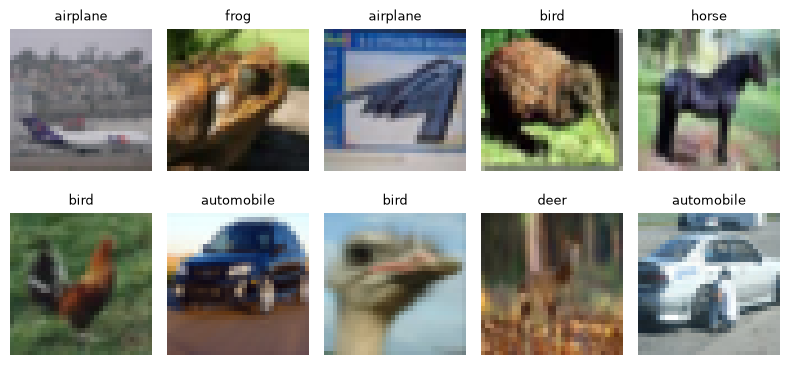

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 32, 32, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 32, 32, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 16, 16, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 16, 16, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 8, 8, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 8, 8, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 8, 8, 128)           │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 4, 4, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         262,272 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 357,706 (1.36 MB)

 Trainable params: 357,258 (1.36 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 154s 209ms/step - accuracy: 0.4859 - loss: 1.4525 - val_accuracy: 0.5562 - val_loss: 1.2552
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 145s 206ms/step - accuracy: 0.6237 - loss: 1.0542 - val_accuracy: 0.5338 - val_loss: 1.4671
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 143s 203ms/step - accuracy: 0.6810 - loss: 0.9005 - val_accuracy: 0.5434 - val_loss: 1.3537
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 202s 203ms/step - accuracy: 0.7139 - loss: 0.8083 - val_accuracy: 0.5686 - val_loss: 1.2087
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 142s 202ms/step - accuracy: 0.7405 - loss: 0.7373 - val_accuracy: 0.6380 - val_loss: 1.0086
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 143s 204ms/step - accuracy: 0.7578 - loss: 0.6835 - val_accuracy: 0.6848 - val_loss: 0.8913
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 145s 206ms/step - accuracy: 0.7744 - loss: 0.6404 - val_accuracy: 0.7016 - val_loss: 0.8883
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 205s 211ms/step - accuracy: 0.7912 -

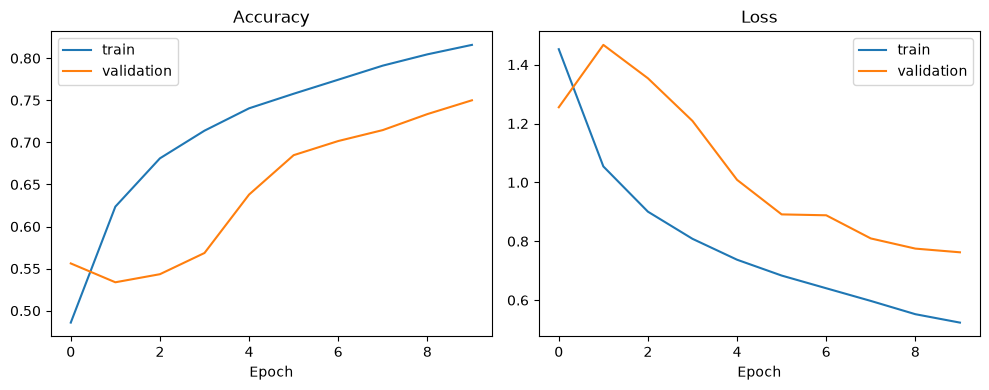

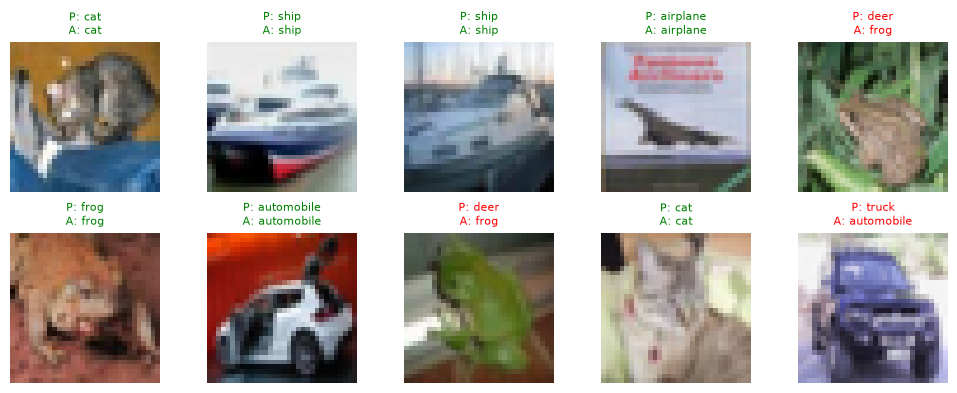

Model saved as cifar10_cnn.h5


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

# ---------- 1. Load data ----------
# Explanation: CIFAR-10 has 60,000 colour images (32 x 32) in 10 classes.
# 50,000 for training and 10,000 for testing.
try:
    # Try the normal Keras download first (Toronto server)
    (x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
    print("Loaded from Keras")
except Exception as e:
    # Explanation: if the Toronto server times out, download the same
    # dataset from Hugging Face and convert it to the same shapes
    print("Keras download failed, using Hugging Face instead...")
    from datasets import load_dataset
    cifar = load_dataset("uoft-cs/cifar10")
    x_train = np.stack([np.array(img) for img in cifar["train"]["img"]])
    y_train = np.array(cifar["train"]["label"]).reshape(-1, 1)
    x_test  = np.stack([np.array(img) for img in cifar["test"]["img"]])
    y_test  = np.array(cifar["test"]["label"]).reshape(-1, 1)

class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]
print("Train:", x_train.shape, " Test:", x_test.shape)

# ---------- 2. Normalize ----------
# Explanation: pixel values 0-255 -> 0-1, so training is faster and stable
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

# ---------- 3. Show some sample images ----------
plt.figure(figsize=(8, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]], fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

# ---------- 4. Build the CNN ----------
# Explanation: Conv2D finds patterns (edges, shapes), MaxPooling shrinks the image,
# BatchNormalization keeps training stable, Dropout reduces overfitting
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    # Explanation: 10 neurons + softmax = probability for each of the 10 classes
    layers.Dense(10, activation="softmax")
])
model.summary()

# ---------- 5. Compile ----------
# Explanation: sparse_categorical_crossentropy because labels are numbers 0-9
# (not one-hot encoded)
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

# ---------- 6. Train ----------
# Explanation: EarlyStopping stops training when validation loss stops improving
early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
history = model.fit(x_train, y_train,
                    epochs=10, batch_size=64,
                    validation_split=0.1,
                    callbacks=[early_stop])

# ---------- 7. Evaluate on test data ----------
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nTest Accuracy: {test_acc:.4f}")

# ---------- 8. Plot accuracy and loss ----------
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy"); plt.xlabel("Epoch"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()
plt.tight_layout()
plt.show()

# ---------- 9. Predict some test images ----------
pred = model.predict(x_test[:10], verbose=0)
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i])
    p = np.argmax(pred[i])
    actual = y_test[i][0]
    color = "green" if p == actual else "red"
    plt.title(f"P: {class_names[p]}\nA: {class_names[actual]}", color=color, fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

# ---------- 10. Save the model ----------
model.save("cifar10_cnn.h5")
print("Model saved as cifar10_cnn.h5")

## 4. Face Mask Detection – Real-Time Webcam Classifier
### Question
**Problem:** Build a real-time face mask detector using a trained CNN model and OpenCV.

### Answer

In [1]:
import os
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

PROJECT_DIR = r"C:\HOPE AI\AI TAMIL COURSE\DEEP LEARNING\Facemask"
IMG_SIZE = 128
BATCH = 32

# ---------- 1. Find the dataset folder ----------
# Explanation: looks for a folder that contains both "with_mask" and "without_mask"
DATA_DIR = None
for root, dirs, files in os.walk(PROJECT_DIR):
    if "with_mask" in dirs and "without_mask" in dirs:
        DATA_DIR = root
        break
if DATA_DIR is None:
    raise FileNotFoundError("Could not find with_mask / without_mask folders inside the Facemask folder.")
print("Dataset folder:", DATA_DIR)
print("With mask   :", len(os.listdir(os.path.join(DATA_DIR, "with_mask"))))
print("Without mask:", len(os.listdir(os.path.join(DATA_DIR, "without_mask"))))

# ---------- 2. Load images (80% train, 20% validation) ----------
# Explanation: only the 2 mask folders are used; labels: with_mask = 0, without_mask = 1
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, class_names=["with_mask", "without_mask"],
    validation_split=0.2, subset="training", seed=42,
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH, label_mode="binary")
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, class_names=["with_mask", "without_mask"],
    validation_split=0.2, subset="validation", seed=42,
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH, label_mode="binary")

# Explanation: scale pixels 0-255 -> 0-1 (the webcam code does the same "/ 255.0")
train_ds = train_ds.map(lambda x, y: (x / 255.0, y))
val_ds   = val_ds.map(lambda x, y: (x / 255.0, y))

# ---------- 3. Build a small CNN ----------
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    # Explanation: 1 neuron + sigmoid = probability of "without_mask"
    layers.Dense(1, activation="sigmoid")
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

# ---------- 4. Train ----------
early_stop = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
model.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=[early_stop])

loss, acc = model.evaluate(val_ds, verbose=0)
print(f"Validation Accuracy: {acc:.4f}")

# ---------- 5. Save ----------
# Explanation: saved in the notebook folder AND the Facemask folder
model.save("mask_detector.h5")
model.save(os.path.join(PROJECT_DIR, "mask_detector.h5"))
print("Saved mask_detector.h5")

Dataset folder: C:\HOPE AI\AI TAMIL COURSE\DEEP LEARNING\Facemask\dataset
With mask   : 3725
Without mask: 3828
Found 7553 files belonging to 2 classes.
Using 6043 files for training.
Found 7553 files belonging to 2 classes.
Using 1510 files for validation.
Epoch 1/5


C:\Users\nisha\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


189/189 ━━━━━━━━━━━━━━━━━━━━ 72s 364ms/step - accuracy: 0.8433 - loss: 0.3612 - val_accuracy: 0.9060 - val_loss: 0.2290
Epoch 2/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 67s 353ms/step - accuracy: 0.9050 - loss: 0.2309 - val_accuracy: 0.9179 - val_loss: 0.1887
Epoch 3/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 66s 345ms/step - accuracy: 0.9290 - loss: 0.1867 - val_accuracy: 0.9404 - val_loss: 0.1622
Epoch 4/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 82s 345ms/step - accuracy: 0.9409 - loss: 0.1535 - val_accuracy: 0.9497 - val_loss: 0.1311
Epoch 5/5
189/189 ━━━━━━━━━━━━━━━━━━━━ 65s 344ms/step - accuracy: 0.9509 - loss: 0.1252 - val_accuracy: 0.9450 - val_loss: 0.1361


Validation Accuracy: 0.9497


Saved mask_detector.h5


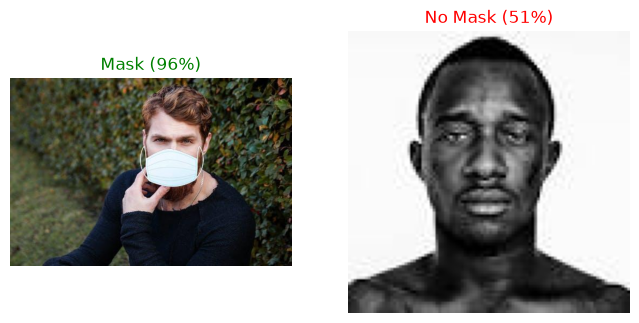

In [2]:
import os, glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model

PROJECT_DIR = r"C:\HOPE AI\AI TAMIL COURSE\DEEP LEARNING\Facemask"

# 1. Load the model you just trained
model = load_model("mask_detector.h5")
IMG_SIZE = model.input_shape[1]

# 2. Pick test photos automatically from your dataset (1 with mask, 1 without)
photos = []
for folder in ["with_mask", "without_mask"]:
    files = glob.glob(os.path.join(PROJECT_DIR, "**", folder, "*.*"), recursive=True)
    photos.append(files[0])

# 3. Predict and show each photo
plt.figure(figsize=(8, 4))
for i, path in enumerate(photos):
    img = cv2.imread(path)
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    x = cv2.resize(rgb, (IMG_SIZE, IMG_SIZE)) / 255.0
    x = np.expand_dims(x, axis=0)
    p = model.predict(x, verbose=0)[0][0]

    if p < 0.5:
        label = f"Mask ({(1 - p) * 100:.0f}%)"
        color = "green"
    else:
        label = f"No Mask ({p * 100:.0f}%)"
        color = "red"

    plt.subplot(1, 2, i + 1)
    plt.imshow(rgb)
    plt.title(label, color=color)
    plt.axis("off")

plt.show()

## 5. Custom Transfer Learning with Frozen + Trainable Layers
### Question
**Problem:** Load a pretrained MobileNetV2 model, freeze base layers, add custom classifier, and fine-tune the top few layers.

### Answer

In [4]:
import os
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

PROJECT_DIR = r"C:\HOPE AI\AI TAMIL COURSE\DEEP LEARNING\Facemask"
IMG_SIZE = (224, 224)
BATCH = 32

# ---------- 0. Find the dataset folder automatically ----------
# Explanation: looks for the folder that has "with_mask" and "without_mask" inside
DATA_DIR = None
for root, dirs, files in os.walk(PROJECT_DIR):
    if "with_mask" in dirs and "without_mask" in dirs:
        DATA_DIR = root
        break
print("Dataset folder:", DATA_DIR)

# ---------- 1. Load dataset (80% train, 20% validation) ----------
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, class_names=["with_mask", "without_mask"],
    validation_split=0.2, subset="training", seed=42,
    image_size=IMG_SIZE, batch_size=BATCH, label_mode="categorical")
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, class_names=["with_mask", "without_mask"],
    validation_split=0.2, subset="validation", seed=42,
    image_size=IMG_SIZE, batch_size=BATCH, label_mode="categorical")
num_classes = len(train_ds.class_names)
print("Classes:", train_ds.class_names)

# Explanation: MobileNetV2 needs pixels scaled to -1..1 using its own preprocess_input
train_ds = train_ds.map(lambda x, y: (preprocess_input(x), y))
val_ds = val_ds.map(lambda x, y: (preprocess_input(x), y))

# ---------- 2. Load pretrained MobileNetV2 without its top layer ----------
base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))

# ---------- 3. Freeze ALL base layers first ----------
base_model.trainable = False

# ---------- 4. Add custom classifier ----------
x = GlobalAveragePooling2D()(base_model.output)   # feature maps -> one vector
x = Dense(128, activation="relu")(x)
x = Dropout(0.3)(x)                               # reduces overfitting
output = Dense(num_classes, activation="softmax")(x)
model = Model(inputs=base_model.input, outputs=output)

# ---------- 5. Stage 1 - train only the new classifier ----------
model.compile(optimizer=Adam(learning_rate=1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])
model.fit(train_ds, validation_data=val_ds, epochs=3)

# ---------- 6. Stage 2 - fine-tune the top 20 layers ----------
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Explanation: re-compile with a very small learning rate
model.compile(optimizer=Adam(learning_rate=1e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])
model.fit(train_ds, validation_data=val_ds, epochs=3)

# ---------- 7. Evaluate and save ----------
loss, acc = model.evaluate(val_ds, verbose=0)
print(f"Validation accuracy: {acc:.4f}")
model.save("mobilenetv2_finetuned.h5")
print("Saved mobilenetv2_finetuned.h5")

Dataset folder: C:\HOPE AI\AI TAMIL COURSE\DEEP LEARNING\Facemask\dataset
Found 7553 files belonging to 2 classes.
Using 6043 files for training.
Found 7553 files belonging to 2 classes.
Using 1510 files for validation.
Classes: ['with_mask', 'without_mask']
Epoch 1/3
189/189 ━━━━━━━━━━━━━━━━━━━━ 218s 1s/step - accuracy: 0.9787 - loss: 0.0544 - val_accuracy: 0.9921 - val_loss: 0.0239
Epoch 2/3
189/189 ━━━━━━━━━━━━━━━━━━━━ 168s 890ms/step - accuracy: 0.9911 - loss: 0.0246 - val_accuracy: 0.9828 - val_loss: 0.0499
Epoch 3/3
189/189 ━━━━━━━━━━━━━━━━━━━━ 280s 1s/step - accuracy: 0.9960 - loss: 0.0118 - val_accuracy: 0.9934 - val_loss: 0.0225
Epoch 1/3
189/189 ━━━━━━━━━━━━━━━━━━━━ 268s 1s/step - accuracy: 0.9757 - loss: 0.0662 - val_accuracy: 0.9934 - val_loss: 0.0279
Epoch 2/3
189/189 ━━━━━━━━━━━━━━━━━━━━ 191s 1s/step - accuracy: 0.9899 - loss: 0.0295 - val_accuracy: 0.9927 - val_loss: 0.0243
Epoch 3/3
189/189 ━━━━━━━━━━━━━━━━━━━━ 227s 1s/step - accuracy: 0.9921 - loss: 0.0225 - val_accura

Validation accuracy: 0.9947
Saved mobilenetv2_finetuned.h5


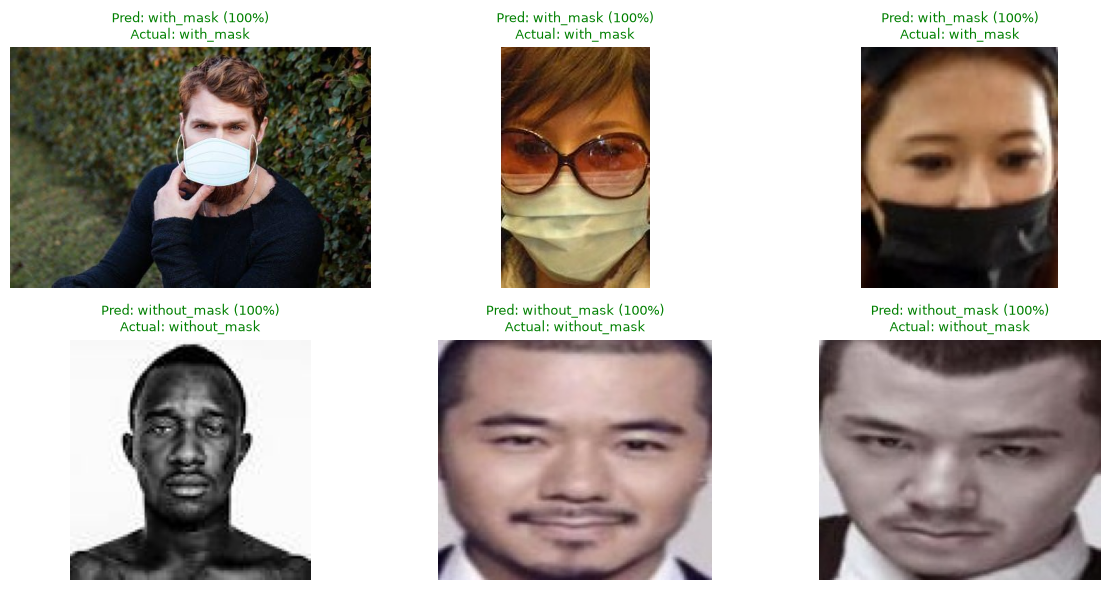

In [5]:
import os, glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

PROJECT_DIR = r"C:\HOPE AI\AI TAMIL COURSE\DEEP LEARNING\Facemask"
class_names = ["with_mask", "without_mask"]

# 1. Load the fine-tuned MobileNetV2 model
model = load_model("mobilenetv2_finetuned.h5")

# 2. Pick 3 photos from each folder automatically
photos = []
for folder in class_names:
    files = glob.glob(os.path.join(PROJECT_DIR, "**", folder, "*.*"), recursive=True)
    photos += [(f, folder) for f in files[:3]]

# 3. Predict and show
plt.figure(figsize=(12, 6))
for i, (path, actual) in enumerate(photos):
    rgb = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)

    # Explanation: same preparation as training -> 224x224 + MobileNetV2 preprocess_input
    x = cv2.resize(rgb, (224, 224)).astype("float32")
    x = preprocess_input(np.expand_dims(x, axis=0))

    # Explanation: softmax gives 2 probabilities; argmax picks the bigger one
    probs = model.predict(x, verbose=0)[0]
    pred = class_names[np.argmax(probs)]
    conf = np.max(probs) * 100

    color = "green" if pred == actual else "red"
    plt.subplot(2, 3, i + 1)
    plt.imshow(rgb)
    plt.title(f"Pred: {pred} ({conf:.0f}%)\nActual: {actual}", color=color, fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()